## phylogenetic reconstruction of population consensus sequences 

## 0. General

### 0.1. load libraries

In [1]:
import os, pandas as pd, dendropy, baltic as blt
from Bio import SeqIO
from Bio.Seq import Seq
from datetime import date


In [2]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.gridspec as gridspec

import seaborn as sns

sns.set_theme(style="white", font="Arial")
sns.set_context({'font.size': 10.0, 'axes.labelsize': 12, 'axes.titlesize': 14,
                 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10,
                 'legend.title_fontsize': None, 'axes.linewidth': 0.8, 'grid.linewidth': 0.8,
                 'lines.linewidth': 1.5, 'lines.markersize': 6.0, 'patch.linewidth': 1.0,
                 'xtick.major.width': 0.5, 'ytick.major.width': 0.5, 'xtick.minor.width': 0.3,
                 'ytick.minor.width': 0.3, 'xtick.major.size': 3.5, 'ytick.major.size': 3.5,
                 'xtick.minor.size': 2.0, 'ytick.minor.size': 2.0,})

plt.rcParams['xtick.bottom'] = True
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['font.size'] = 12
plt.rcParams['xtick.bottom'] = True
plt.rcParams['ytick.left'] = True

### 0.2. general variables

In [3]:
donors = [1,2,3,4]
replicates = ["A", "B", "C"]
passages = list(range(0, 110, 10))
tech_reps = [1,2 ]
populations = ["1A", "1B", "1C", "2A", "2B", "2C", "3A", "3B", "3C", "4A", "4B", "4C"]
segments = ["1-PB2", "2-PB1", "3-PA", "4-HA", "5-NP", "6-NA", "7-M", "8-NS"]

hours_per_passage = 72 #hours
generation_time = 6 #hours > assumption based on Baccam, et al. 2006

In [4]:
segment_nuc_cds = {r.id:r.seq for r in SeqIO.parse('../data/references/stock_consensus_cds.fasta', 'fasta')}


In [5]:
#color palette 
population_cpal = [ "#005fb9", "#58b4e2", "#8ee6ff", "#860041", "#ca0090", "#ff53c0", "#006e00", "#77a908", "#bbe837", "#0000ba", "#5f38ed", "#d49eff" ]


### 0.3. Functions

In [6]:
def nexus_to_newick(treefile):
    Tree = dendropy.Tree.get(path=treefile, schema="nexus")
    new_treefile = treefile.replace(".nexus", ".tree")
    Tree.write(path=new_treefile, schema="newick")
    return new_treefile
    
def load_as_sort_tree_baltic(treefile):
    tree = blt.loadNewick(treefile, absoluteTime=True)
    sort_function =lambda k: (-len(k.leaves),k.length) if k.is_node() else (k.is_node(),k.length)
    tree.sortBranches(descending=False, sort_function=sort_function, sortByHeight=True)
    return tree

def date_to_float_date(d):
    year = d.year
    day_of_year = (d - date(year, 1, 1)).days
    return year + day_of_year / 365


## Phylogenetic reconstruction

### 1. Prep data

In [7]:
phylo_dir = "../results/phylogeny"
phylo_seq_dir = os.path.join(phylo_dir, "sequences")
phylo_tree_dir = os.path.join(phylo_dir, "tree")

for d in [phylo_dir, phylo_seq_dir, phylo_tree_dir]:
    if not os.path.isdir(d):
        os.makedirs(d)
    

In [8]:
#load trajectories 
trajectories = pd.read_csv("../results/snv_trajectories.csv").set_index(["population", "refname", "nucpos", "snv"]).sort_index()
trajectories = trajectories.rename(columns={c:int(c) for c in trajectories.columns})

In [9]:
#get consensus sequence per segment for each pop
for refname in segments:
    stock_seq = segment_nuc_cds[refname]
    
    records = {f"stock_{refname}":stock_seq}
    start_date = pd.Timestamp("2008-05-11")
    records = {f"stock_{refname}|{pd.to_datetime(start_date).date()}":stock_seq}
    
    for population in populations:
        for passage in passages[1:]:
            d = start_date + pd.Timedelta(days=(passage*hours_per_passage)/24)
            d = pd.to_datetime(d).date()
            sample = f"P{passage}-{population}_{refname}|{d}"
            
            snv_list = trajectories.loc[(population, refname)]
            snv_list = snv_list[snv_list[passage]>=0.5].index.tolist()
            
            seq = list(stock_seq)
            for (nucpos, snv) in snv_list:
                seq[nucpos-1] = snv[-1]
                
            seq = Seq("".join(seq))
            
            records[sample] = seq
            
    seq_filename = os.path.join(phylo_seq_dir, f"{refname}_sequences.fasta")
    with open(seq_filename, "w") as fw:
        for k, v in records.items():
            fw.write(f">{k}\n{v}\n")


### 2. Run actual reconstruction 
reconstruction is pretty simple so running it within the notebook rather than writing and running a seperate bash file

In [10]:
threads = 1
iqtree_base_command = f"iqtree -nt {threads} -m GTR+G4 -s "
treetime_base_command = 'treetime --tree _tree --aln _aln --dates _dates --outdir _outdir --clock-rate 0.004383 --clock-std-dev 0.0008766'

#alignment not needed as sequences are all full CDS and therefore already 'aligned'
for refname in segments:
    tree_file = os.path.join(phylo_tree_dir, f"{refname}.tree")
    if not os.path.isfile(tree_file): 
        os.system(iqtree_base_command + seq_filename + f" -o 'stock_{refname}|{pd.to_datetime(start_date).date()}'")
        iqtree_file = seq_filename + ".treefile"
        os.system(f"mv {iqtree_file} {tree_file}")
        files_ex = [".bionj",".ckp.gz",".iqtree",".mldist",".model.gz",".contree",".log",".splits.nex",".uniqueseq.phy",".model", ".parstree"]
        for ex in files_ex:
            if os.path.isfile(seq_filename + ex):
                os.system(f"rm {seq_filename + ex}")
    
  


### 3. Visualize tree

In [11]:
#find identical sequence so nodes can be collapsed
nodes_to_collapse = {refname:{} for refname in segments}
n_unique_tips = {refname:0 for refname in segments}

for refname in segments:
    seq_filename = os.path.join(phylo_seq_dir, f"{refname}_sequences.fasta")
    
    seq_overview = {}
    for r in SeqIO.parse(seq_filename, "fasta"):
        l_lab = "P0" if r.id.startswith("stock") else r.id.split("_")[0]
        if r.seq not in seq_overview.keys():
            seq_overview[r.seq] = [r.id]
        else:
            seq_overview[r.seq].append(r.id)
            
    for l in seq_overview.values():
        l = sorted(l)

        if not l[-1].startswith("stock"):
            
            pop_list = [i.split("_")[0].split("-")[-1] for i in l]
            p_overview = sorted([int(i.split("-")[0].lstrip("P")) for i in l])
            

            if len(set(pop_list))> 1:
                print ("population problem, to code")
                print (pop_list)
                print (l)
                
                
            elif len(l) > 1:
                lab = f"{pop_list[0]}_{p_overview[0]*12}-{p_overview[-1]*12}" 
                
                nodes_to_collapse[refname][lab] = l
            n_unique_tips[refname] += 1


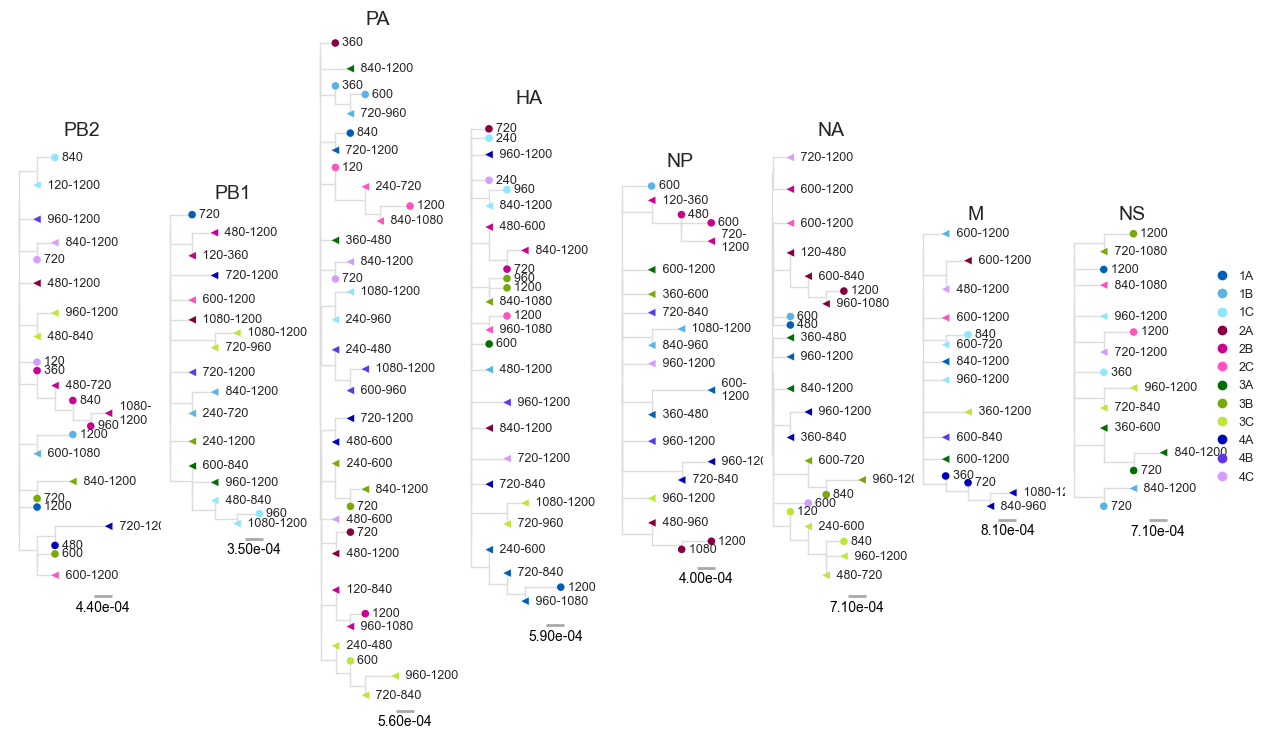

In [12]:
molecular_trees = {}
redo = True
for refname in segments:
    treefile =  os.path.join(phylo_tree_dir, f"{refname}.tree")
    tree = load_as_sort_tree_baltic(treefile)
    molecular_trees [refname] = tree   

for i, refname in enumerate(segments):             
    tree = molecular_trees[refname]
    for k, v in nodes_to_collapse[refname].items():
        try:
            ancestor = tree.commonAncestor(tree.getExternal(lambda k:k.name in v))
            tree.collapseSubtree(ancestor, k , widthFunction=lambda x:len(x.leaves)/2)
        except:
            pass

max_unique_tips = max(n_unique_tips.values())
tree_heights = [tree.treeHeight for k, tree in molecular_trees.items() if k !="genome"]
fig = plt.figure(figsize=(15,11))
gs = gridspec.GridSpec(1,8, wspace=0.4, hspace=0.65)

gs_PB2 = gridspec.GridSpecFromSubplotSpec(3,1, wspace=0.35, hspace=0.23, subplot_spec=gs[0],
                                          height_ratios = [(((max_unique_tips-n_unique_tips["1-PB2"])/max_unique_tips)/2), (n_unique_tips["1-PB2"]/max_unique_tips), (((max_unique_tips-n_unique_tips["1-PB2"])/max_unique_tips)/2)])
gs_PB1 = gridspec.GridSpecFromSubplotSpec(3,1, wspace=0.35, hspace=0.23, subplot_spec=gs[1],
                                          height_ratios = [(((max_unique_tips-n_unique_tips["2-PB1"])/max_unique_tips)/2), (n_unique_tips["2-PB1"]/max_unique_tips), (((max_unique_tips-n_unique_tips["2-PB1"])/max_unique_tips)/2)])
gs_PA = gridspec.GridSpecFromSubplotSpec(3,1, wspace=0.35, hspace=0.23, subplot_spec=gs[2],
                                          height_ratios = [(((max_unique_tips-n_unique_tips["3-PA"])/max_unique_tips)/2), (n_unique_tips["3-PA"]/max_unique_tips), (((max_unique_tips-n_unique_tips["3-PA"])/max_unique_tips)/2)])
gs_HA = gridspec.GridSpecFromSubplotSpec(3,1, wspace=0.35, hspace=0.23, subplot_spec=gs[3],
                                          height_ratios = [(((max_unique_tips-n_unique_tips["4-HA"])/max_unique_tips)/2), (n_unique_tips["4-HA"]/max_unique_tips), (((max_unique_tips-n_unique_tips["4-HA"])/max_unique_tips)/2)])
gs_NP = gridspec.GridSpecFromSubplotSpec(3,1, wspace=0.35, hspace=0.23, subplot_spec=gs[4],
                                          height_ratios = [(((max_unique_tips-n_unique_tips["5-NP"])/max_unique_tips)/2), (n_unique_tips["5-NP"]/max_unique_tips), (((max_unique_tips-n_unique_tips["5-NP"])/max_unique_tips)/2)])
gs_NA = gridspec.GridSpecFromSubplotSpec(3,1, wspace=0.35, hspace=0.23, subplot_spec=gs[5],
                                          height_ratios = [(((max_unique_tips-n_unique_tips["6-NA"])/max_unique_tips)/2), (n_unique_tips["6-NA"]/max_unique_tips), (((max_unique_tips-n_unique_tips["6-NA"])/max_unique_tips)/2)])
gs_M = gridspec.GridSpecFromSubplotSpec(3,1, wspace=0.35, hspace=0.23, subplot_spec=gs[6],
                                          height_ratios = [(((max_unique_tips-n_unique_tips["7-M"])/max_unique_tips)/2), (n_unique_tips["7-M"]/max_unique_tips), (((max_unique_tips-n_unique_tips["7-M"])/max_unique_tips)/2)])
gs_NS = gridspec.GridSpecFromSubplotSpec(3,1, wspace=0.35, hspace=0.23, subplot_spec=gs[7],
                                          height_ratios = [(((max_unique_tips-n_unique_tips["8-NS"])/max_unique_tips)/2), (n_unique_tips["8-NS"]/max_unique_tips), (((max_unique_tips-n_unique_tips["8-NS"])/max_unique_tips)/2)])

axes = [fig.add_subplot(gs_PB2[1]), fig.add_subplot(gs_PB1[1]), fig.add_subplot(gs_PA[1]), fig.add_subplot(gs_HA[1]),
        fig.add_subplot(gs_NP[1]), fig.add_subplot(gs_NA[1]), fig.add_subplot(gs_M[1]), fig.add_subplot(gs_NS[1])]

#manually fixing some of the node labelling
rename_nodes = {"1-PB2":{"2B_1080-1200":"1080-\n   1200", "5A_720-1200":"720-\n   1200"},
                "2-PB1":{},
                "3-PA":{},
                "4-HA":{},
                "5-NP":{"1A_600-1200":"600-\n   1200", "2B_720-1200":"720-\n   1200", "5A_960-1200":"960-\n   1200"},
                "6-NA":{"4B_960-1200":"960-\n   1200"},
                "7-M":{"5A_1080-1200":"1080-\n   1200", "5A_840-960":"840-\n   960"},
                "8-NS":{"4A_840-1200":"840-\n   1200"}}

for i, refname in enumerate(segments):
    tree_ax = axes[i]
                   
    tree = molecular_trees[refname]
    root_height = tree.root.height
  
    x_attr = lambda k: k.height
    color_dict_population = {p:population_cpal[i] for i, p in enumerate(populations)}
    color_dict_population["stock"] = "#DDDDDD"
    c_func= lambda k: color_dict_population[k.name.split("_")[0].split("-")[-1]]
    target_func = lambda k: k.height != root_height 
    target_func = lambda k: k.height != root_height #or  (k.branchType=="leaf" and "P10-1A" not in k.name and k.height != root_height)
    
    
    tree.plotTree(tree_ax,  x_attr=x_attr,  target=target_func, colour="#DDDDDD", width=1 )
    kwargs={'va':'center','ha':'left','size':9}

    target_func=lambda k: k.branchType=='leaf' ## only target nodes

    #if hasattr(k, 'name') and k.name else ""
    #target_func = lambda k:  k.branchType=='leaf' and not isinstance(k, blt.clade)
    target_func = lambda k: k.height != root_height and k.branchType=='leaf' and not isinstance(k, blt.clade)# and "P10-1A" not in k.name
    target_func = lambda k: k.branchType=='leaf' and ((k.height > root_height and "P10-1A" not in k.name ))  and not isinstance(k, blt.clade)
    #target_func = lambda k: k.branchType=='leaf' and ((k.height > root_height ))  and not isinstance(k, blt.clade)
    
    tree.plotPoints(tree_ax, x_attr=x_attr, target=target_func, colour=c_func, size=30, outline=False)
    text_func=lambda k: "  " + str(int((int(k.name.split("_")[0].split("-")[0].lstrip("P"))*hours_per_passage)/generation_time)) \
        if "stock" not in k.name else '0'
    tree.addText(tree_ax,x_attr=x_attr,target=target_func,text=text_func,**kwargs) ## text
    
    
    target_func = lambda k: k.height != root_height and isinstance(k, blt.clade) and  not (k.branchType=="leaf" and "P10-1A"  in k.name )
    text_func=lambda k: "   " + k.name.split("_")[-1].replace(",", ",\n  ") if k.name not in rename_nodes[refname].keys() else "   " + rename_nodes[refname][k.name]
    tree.plotPoints(tree_ax, x_attr=x_attr, target=target_func, colour=c_func, size=30, outline=False, marker="<")
    tree.addText(tree_ax,x_attr=x_attr,target=target_func,text=text_func,**kwargs) ## text
    
    #min_y = min([k.y for k in tree.Objects if k.height != root_height])

    #tree_ax.set_ylim(min_y-2, tree.ySpan+2)
    
    
    tree_ax.set_xticks([])
    tree_ax.set_xlim((-tree.treeHeight*0.1),tree.treeHeight+tree.treeHeight*0.1)
    tree_ax.get_yaxis().set_visible(False)
    tree_ax.spines[['left','right','top', 'bottom']].set_visible(False)

    #tree_ax.grid(axis='x', linestyle='--', alpha=0.5, color='#dddddd', zorder=-1000)

    scale_length = round(tree.treeHeight*0.2,5) 
    xlim = tree_ax.get_xlim()
    ylim = tree_ax.get_ylim()
    bar_x = (xlim[1] - xlim[0]) * 0.7
    bar_y = ylim[0] if refname != "3-PA" else ylim[0]+2
    tree_ax.plot( [bar_x, bar_x + scale_length], [bar_y, bar_y],color='darkgrey', linewidth=2, solid_capstyle='butt')
    tree_ax.text( bar_x + scale_length / 2, bar_y - 0.5, f"{scale_length:.2e}", ha='center', va='top', size=10, color='black')

for i, tree_ax in enumerate(axes):
    
    tree_ax.text(0.5, 1 if segments[i].split("-")[-1]!="PA" else 0.98, segments[i].split("-")[-1], size=14, transform=tree_ax.transAxes)
    
legend_elements = []#[Line2D([0], [0], color='white', label="population", linewidth=0,)]
for i, population in enumerate(populations):
    legend_elements.append(Line2D([0], [0], color=population_cpal[i], label=population, linewidth=0, marker="o", markersize=6))


leg = tree_ax.legend(handles=legend_elements, loc='center left', bbox_to_anchor=(1.3,0.5), ncols =1, 
                             fontsize=9, handlelength=1, edgecolor=None, frameon=False, columnspacing=0.5)

fig.savefig("../figures/figE1_phylogenetic_trees.svg", dpi=300,bbox_inches='tight')
fig.savefig("../figures/figE1_phylogenetic_trees.png", dpi=300,bbox_inches='tight') 


**Extended data Figure 1 Segment specific phylogenetic trees from the population consensus sequences at each sampling timepoint (in generations).** 